In [1]:
from src import utils, argparser, linear_RNN, theory, plotting
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import math

In [2]:
bc = plotting.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [12]:
parser = argparser.get_parser()  
args = parser.parse_args('')
args.frozen_input_output = False
args.frozen_hidden_layer = False
delta = 0.5
args.input_size = 3
args.hidden_size = 3
args.output_size = 3
args.num_seeds = 1
args.num_SV = 3
args.trajectory_length= 5
args.inout_mode_init = [0.7 - delta, 1 - delta, (1/(1.1**args.trajectory_length)) - delta]
args.rec_mode_init = [1, 0.7, 1/1.1]
args.lr = 5
args.num_epochs = 10000

In [13]:
S = torch.zeros((args.trajectory_length, args.output_size, args.input_size)) 
for t in range(1, args.trajectory_length+1):
    t_S = torch.tensor([0.7, 0.7**(args.trajectory_length-t), 1.1**t]) #  0.7**t, 
    S[t-1] = torch.diag(t_S) 
    # soln for b at [1, 0.7, 1/1.1 ~0.9]
args.S = S
args.num_seeds = 1

args, X, y = utils.generate_data(args)

tape = utils.get_tape_module(args)

args.inout_mode_init = torch.tensor(args.inout_mode_init)
args.rec_mode_init = torch.tensor(args.rec_mode_init)

W_x, W_h, W_y, dW_x, dW_h, dW_y, R_y, R_x = utils.initialize_student(args)

tape.W_x[0,0] = W_x.detach().numpy()
tape.W_h[0,0] = W_h.detach().numpy()
tape.W_y[0,0] = W_y.detach().numpy()
tape.dW_x[0,0] = dW_x.detach().numpy()
tape.dW_h[0,0] = dW_h.detach().numpy()
tape.dW_y[0,0] = dW_y.detach().numpy()
tape.R_y[0,0] = R_y.detach().numpy()
tape.R_x[0,0] = R_x.detach().numpy()

tensor(0.7111)


In [14]:
model = linear_RNN.LinearRNN(args, init_W_x = W_x, init_W_h = W_h, init_W_y = W_y)
losses, W_x_ar, W_h_ar, W_y_ar, H_ar, W_x_grad_ar, W_h_grad_ar = model.train(X,y) ## add tape to model
a_sim,b_sim,c_sim,u_sim = model.project_SVD_space(W_x_ar, W_h_ar, W_y_ar, tape)

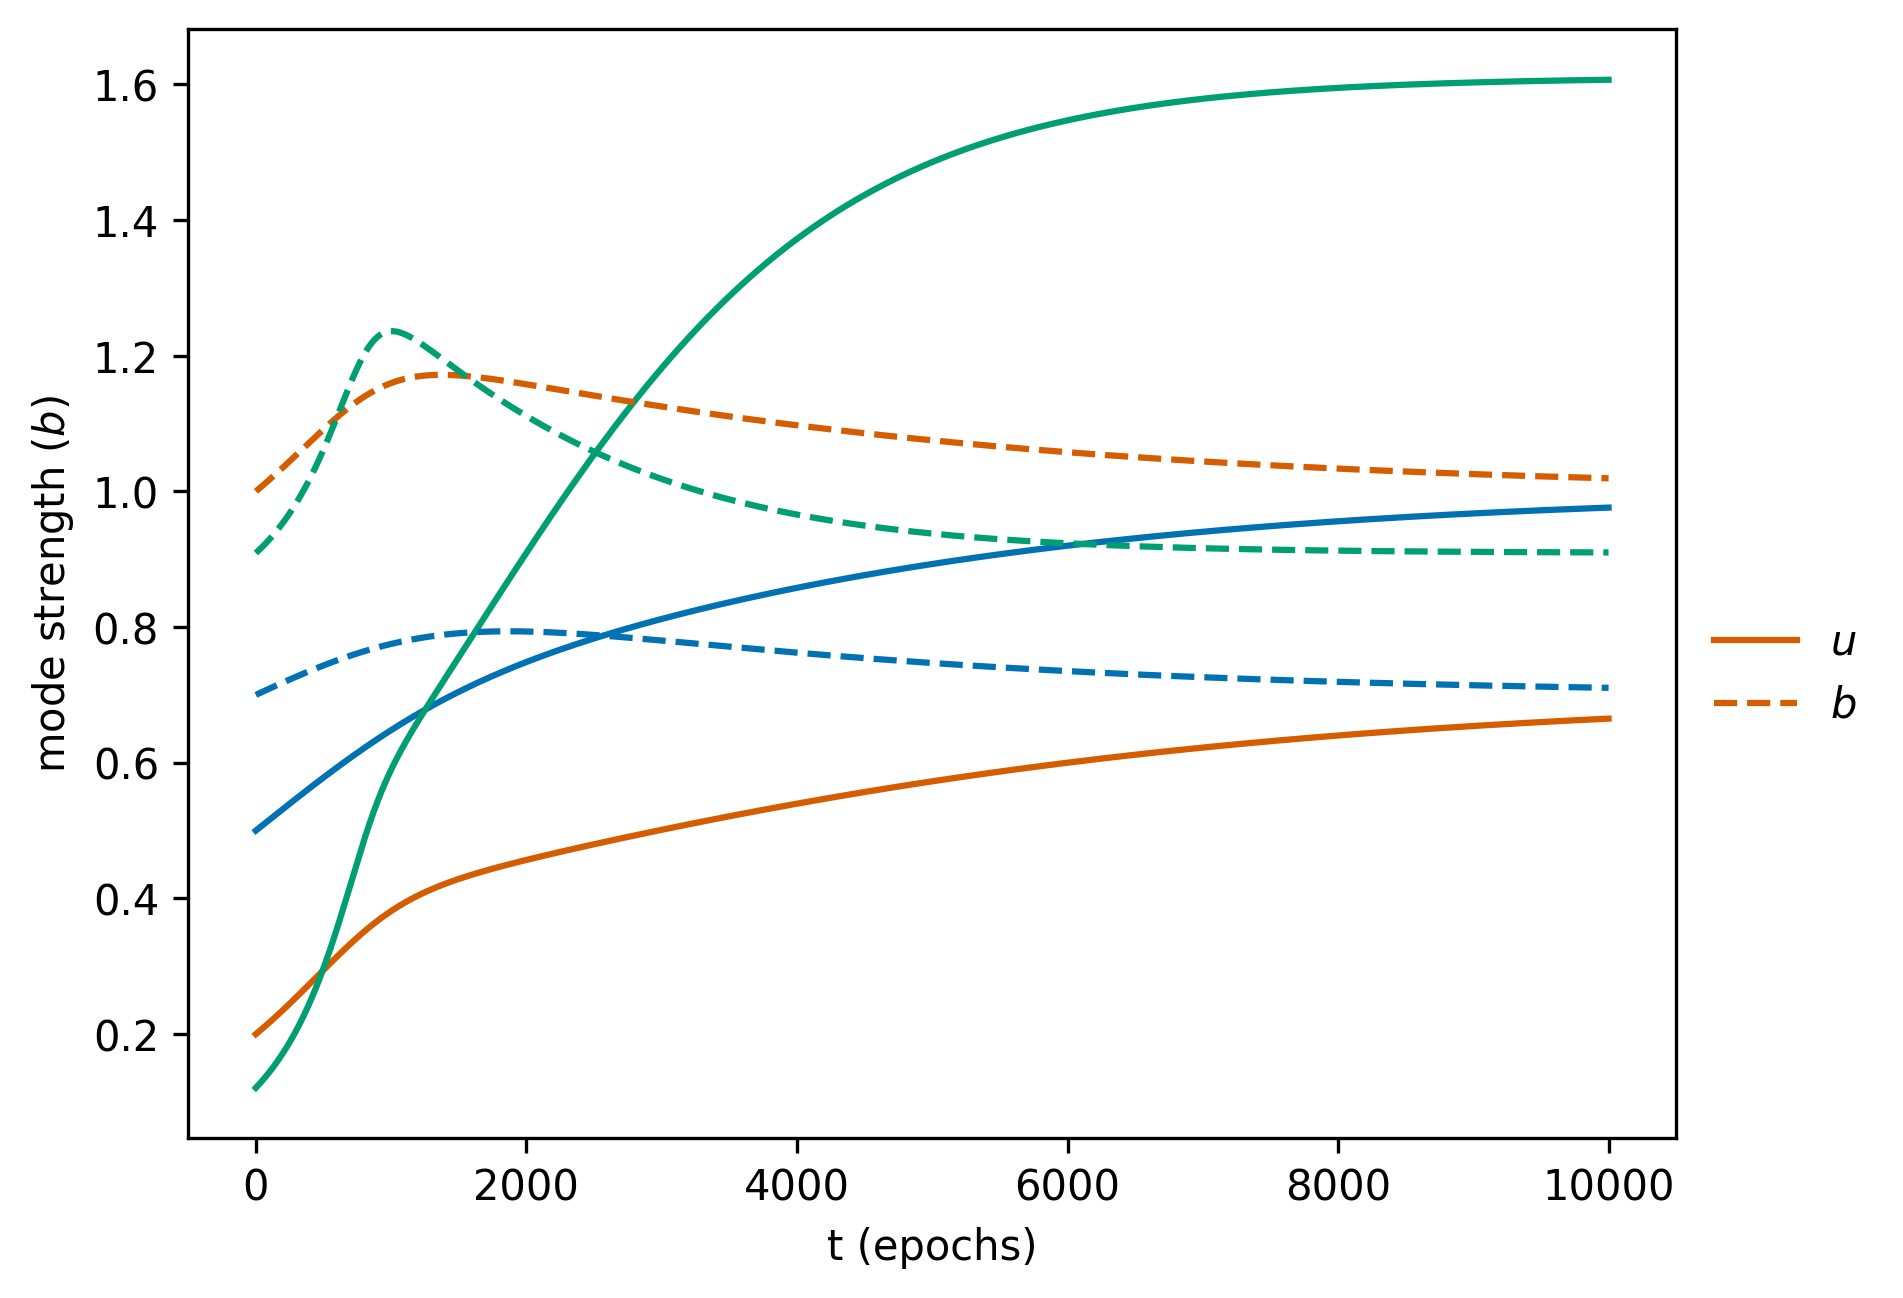

In [15]:
# delta in u

fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(u_sim[:,0], label=r'$u$', color=blind_colors[0])
plt.plot(u_sim[:,1], color=blind_colors[1])
plt.plot(u_sim[:,2], color=blind_colors[2])
plt.plot(b_sim[:,0], label=r'$b$', color=blind_colors[0], ls='dashed',)
plt.plot(b_sim[:,1], color=blind_colors[1], ls='dashed',)
plt.plot(b_sim[:,2], color=blind_colors[2], ls='dashed',)
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'mode strength ($b$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])

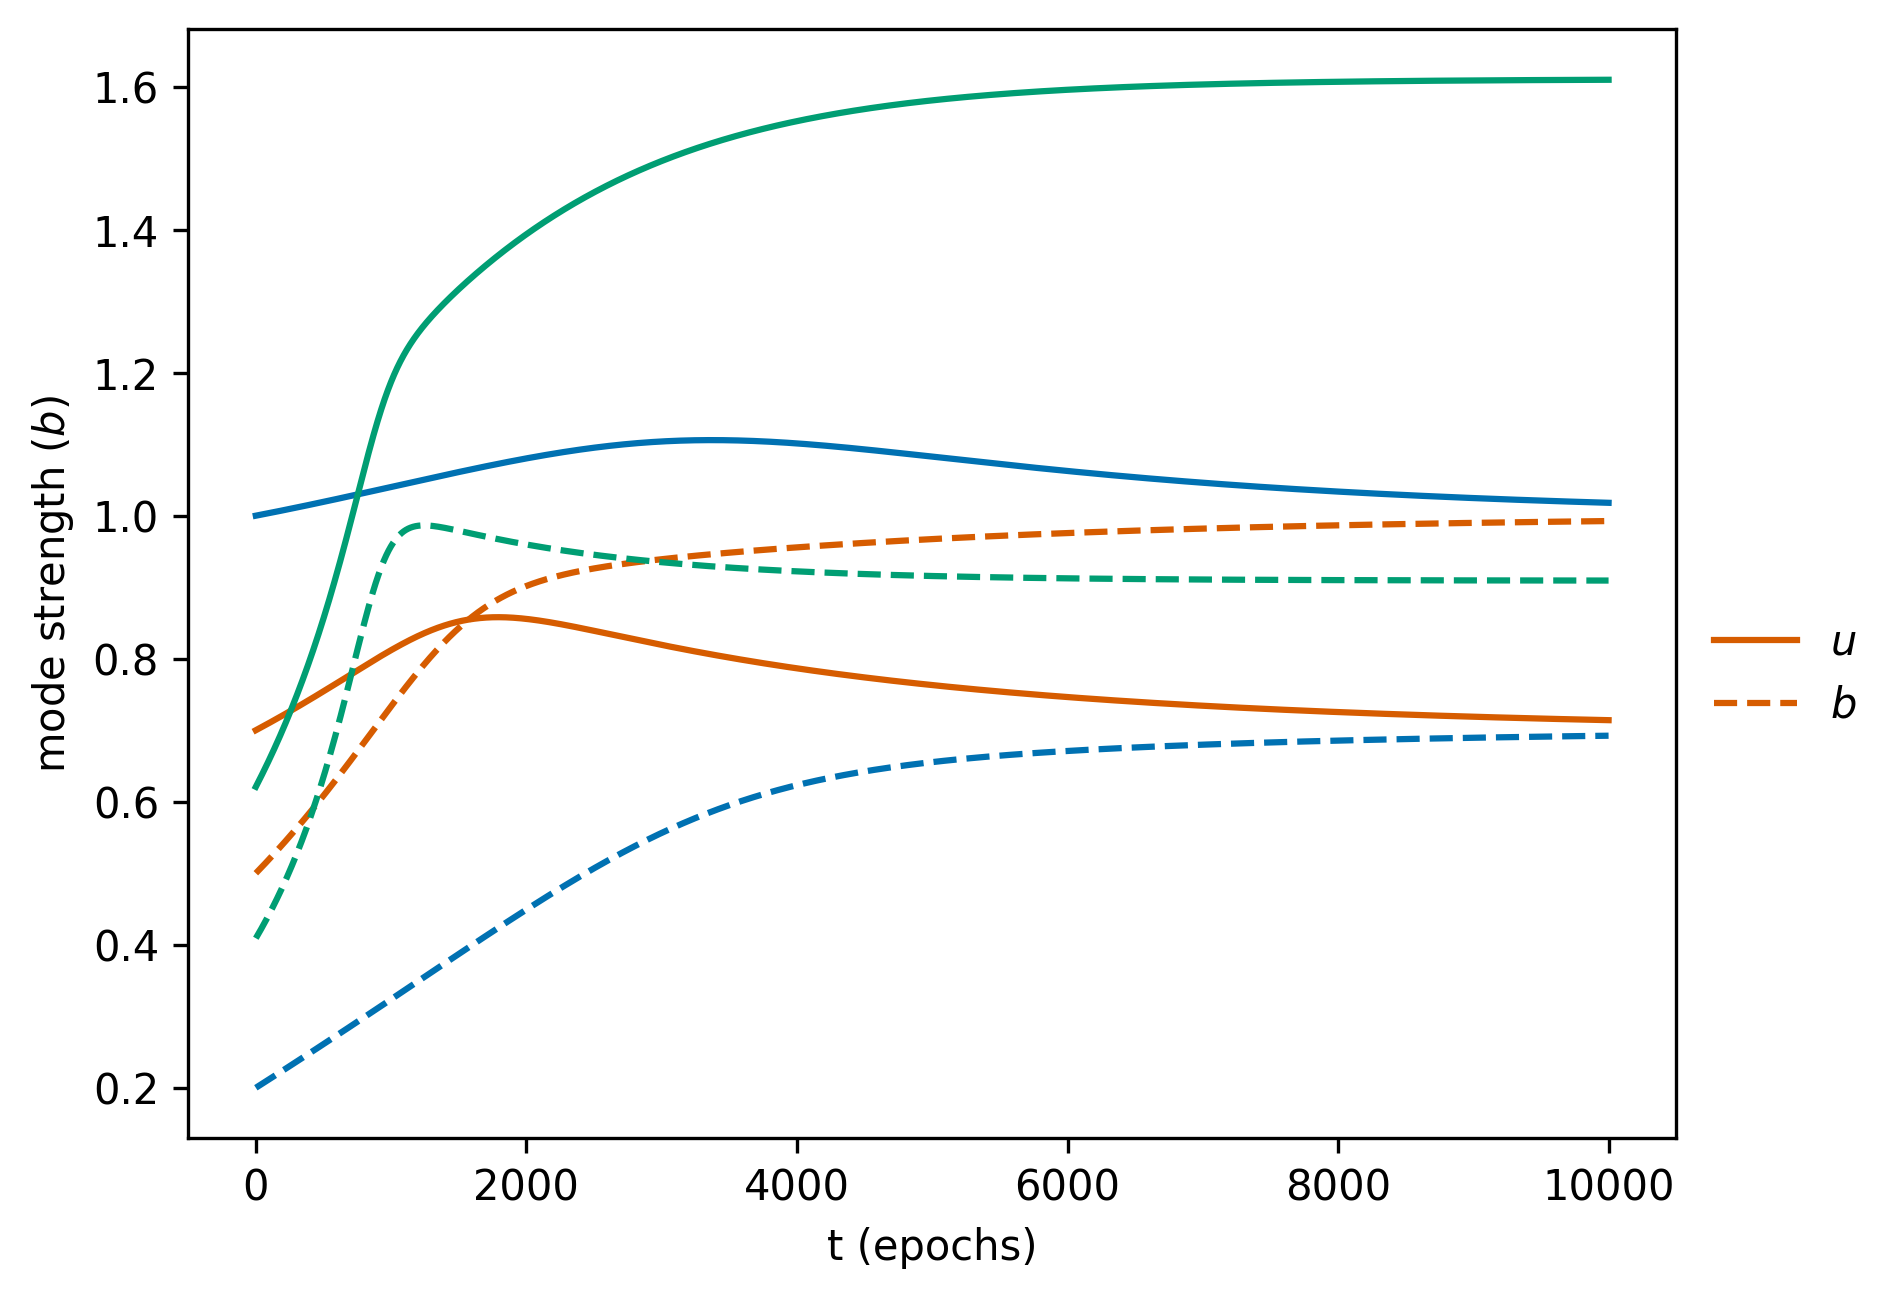

In [11]:
# delta in b

fig = plt.figure(dpi=300)
ax = fig.add_subplot(111)
plt.plot(u_sim[:,0], label=r'$u$', color=blind_colors[0])
plt.plot(u_sim[:,1], color=blind_colors[1])
plt.plot(u_sim[:,2], color=blind_colors[2])
plt.plot(b_sim[:,0], label=r'$b$', color=blind_colors[0], ls='dashed',)
plt.plot(b_sim[:,1], color=blind_colors[1], ls='dashed',)
plt.plot(b_sim[:,2], color=blind_colors[2], ls='dashed',)
ax.set_xlabel('t (epochs)')
ax.set_ylabel(r'mode strength ($b$)')
ax.legend(frameon=False, bbox_to_anchor=(1, 0.5))
# ax.set_yticks([0.0, 0.2])